### Module 1 — State fundamentals

Core idea: State is the information a system needs to remember between operations.

Consider a document retrieval workflow:
#### Example 1: State is defined using a Python dictionary

In [ ]:
state = {
    "task": "Search documents",
    "status": "pending",
    "documents": [],
    "retry_count": 0,
    "results": []
}

def execute(state):
    state["results"].append("Document A")
    state["status"] = "Completed"

print (f"state\n.. \n...")
execute(state)
print (state)

state
.. 
...
{'task': 'Search documents', 'status': 'Completed', 'results': ['Document A']}


Conclusion: The dictionary is mutable. The function modifies the original state object. 

#### Example 2: Avoid modifying the original state

In [6]:
def execute(state):
    return {
        **state, 
        "status": "completed"
    }

old = {"status": "pending"}
new = execute(old)

print (old)
print (new)

{'status': 'pending'}
{'status': 'completed'}


This creates a new top-level dictionary. Note that nested objects are still shared unless copied separately. 

Interview takeaway: Mutable state is convenient, but explicit state updates are easier to reason about, test, and audit.

### Module 2 - Concurrent State

The main challenge is that multiple tasks may attempt to update shared state simultaneously. 

In [ ]:
import asyncio 

state = {"counter": 0}

async def increment():
    current = state["counter"]
    await asyncio.sleep(5)
    state["counter"] = current + 1

async def main():
    await asyncio.gather(increment(), increment())
    print (state)

await main()
# Both coroutines read 0 before either writes the new value. The correct count should be 2. So fix with an asyncio lock    

{'counter': 1}


In [12]:
import asyncio 

state = {"counter": 0}
lock = asyncio.Lock() 

async def increment():
    async with lock: 
        current = state["counter"]
        await asyncio.sleep(0)
        state["counter"] = current + 1

async def main():
    await asyncio.gather(increment(), increment())
    print (state)

await main()

{'counter': 2}


Now the increments are serialized. 

Interview takeaway: asyncio.Lock protects shared state between coroutines in the same event loop. It is not a distributed lock across separate processes or machines.



### Module 3 - Multi-agent state 

We'll implement a thre-stage workflow. 


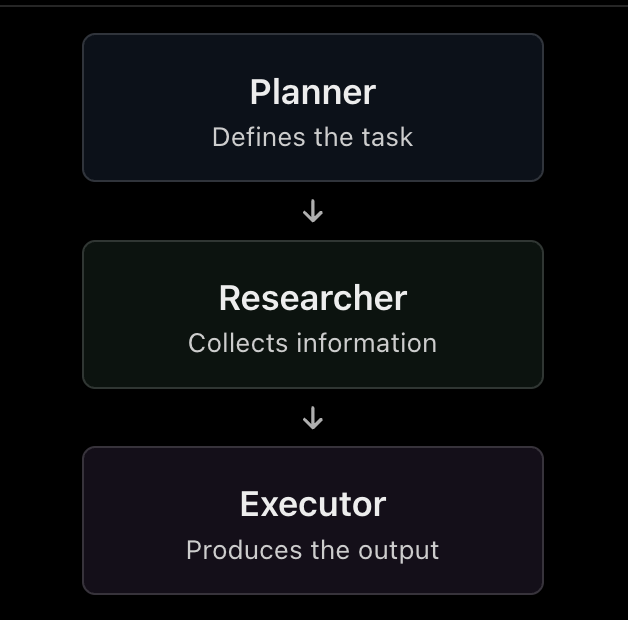


In [9]:
state = {"query": "Sweden Leave Policy"}

def planner(s):
    s["plan"] = "Find relevant policy"
    return s

def researcher(s):
    s["documents"] = ["Leave Policy 2026"]
    return s 

def executor(s):
    s["answer"] = f"Found '{s['documents'][0]}!'"
    return s 

for agent in (planner, researcher, executor):
    print (state)
    state = agent(state)
print ()
print (state["answer"])

{'query': 'Sweden Leave Policy'}
{'query': 'Sweden Leave Policy', 'plan': 'Find relevant policy'}
{'query': 'Sweden Leave Policy', 'plan': 'Find relevant policy', 'documents': ['Leave Policy 2026']}

Found 'Leave Policy 2026!'


#### The above code demonstrates a basic sequential multi-agent workflow (often used in AI frameworks like LangGraph or custom pipeline designs).

Instead of one massive function doing everything, the task is broken down into small, specialized functions called agents (or nodes) that pass a shared state dictionary from one to the next.

#### Here is a step-by-step breakdown of how it works:

**1. The shared state**

        state = {"query": "Sweden Leave Policy"}

Everything revolves arounf the state dictionary. It acts as the "short-term memory" or central database for the workflow. Every agent reads from this dictionary, updates it, and passes it forward.

**2. The Agents (i.e. the functions)**

Here, each function represents an autonomous worker that performs one specific task: 

        * planner(s): Receives the state, adds a "plan" key to log what needs to be done, and returns the updated state. 

        * researcher(s): Receives the state, mimics searching for data, adds a 'documents' key containing the search results, and returns the state. 

        * executor(s): Receives the state, reads the documents that the researcher found i.e. "s['documents'][0]", creaets a final "anwer", and returns the state

**3. The Execution Loop (the pipeline)**

The loop run the agents in sequential order. 

        1. state goes into planner -> comes out with a plan 

        2. state goes into researcher -> comes out with a plan and documents.

        3. state goes into executor -> comes with a plan, documents, and the final answer

**What happens to the state at each step:**


Step	                State Dictionary Content

Initial	                {"query": "Sweden Leave Policy"}

After planner	        {   "query": "Sweden Leave Policy", 
                            "plan": "Find relevant policy"}

After researcher	    {   "query": "Sweden Leave Policy", 
                            "plan": "Find relevant policy", 
                            "documents": ["Leave Policy 2026"]}

After executor	        {   "query": "Sweden Leave Policy", 
                            "plan": "Find relevant policy", 
                            "documents": ["Leave Policy 2026"], 
                            "answer": "Found 'Leave Policy 2026!'"}


The takeaway: 

Each step reads the workflow state, performs work, and contributes updates for subsequent steps. In production, define a state schema, validate transitions, and control who may update which fields.

### Module 4 - LangGraph vs AWS Step Functions 

Capability                       LangGraph                          AWS Step Functions

State Handling                  Graph state between nodes           JSOn execution state

Execution                       Application runtime                 AWS-managed workflow service

Checkpointing                   Supported using checkpointers       Durable execution history for standard workflows

Retries                         Configurable per node               Retry/Catch Policies

Human Approval                  Interrup / resume patterns          Callback / Task token patterns 

Agent loops                     Natural Graph Cycles                Choice State and workflow loops 

Main Advantage                  Agent centric orchestration         Managed Service Orchestration

The important distinction isn't that one manages state and the other doesn't. Both do, but at different abstraction levels and with different operational trade-offs.
